# Wczytanie modeli

In [1]:
import joblib
import os
import glob

# Wczytanie wszystkich zapisanych modeli
models_dir = 'models'
model_files = glob.glob(os.path.join(models_dir, '*_compression_model.pkl'))

loaded_results = {}

print("Wczytywanie zapisanych modeli...")
print("=" * 70)

for model_path in model_files:
    # Wyciągnij nazwę modelu z nazwy pliku
    model_filename = os.path.basename(model_path)
    # Usuń '_compression_model.pkl' i zamień podkreślniki na spacje
    model_name = model_filename.replace('_compression_model.pkl', '').replace('_', ' ').title()
    
    # Pomiń best_model
    if model_name == 'Best':
        continue
    
    # Wczytaj model
    model = joblib.load(model_path)
    loaded_results[model_name] = {'model': model}
    
    print(f"✓ Wczytano: {model_name}")
    print(f"  Plik: {model_filename}")
    print(f"  Typ: {type(model).__name__}")
    print()

print(f"\nŁącznie wczytano {len(loaded_results)} modeli")
print("=" * 70)


Wczytywanie zapisanych modeli...
✓ Wczytano: Gradient Boosting
  Plik: gradient_boosting_compression_model.pkl
  Typ: GradientBoostingRegressor

✓ Wczytano: Linear Regression
  Plik: linear_regression_compression_model.pkl
  Typ: LinearRegression

✓ Wczytano: Random Forest
  Plik: random_forest_compression_model.pkl
  Typ: RandomForestRegressor

✓ Wczytano: Svr
  Plik: svr_compression_model.pkl
  Typ: SVR


Łącznie wczytano 4 modeli


Dane JFIF wczytane: 11000 próbek
✓ Predykcja wykonana: Gradient Boosting
✓ Predykcja wykonana: Linear Regression
✓ Predykcja wykonana: Random Forest
✓ Predykcja wykonana: Svr



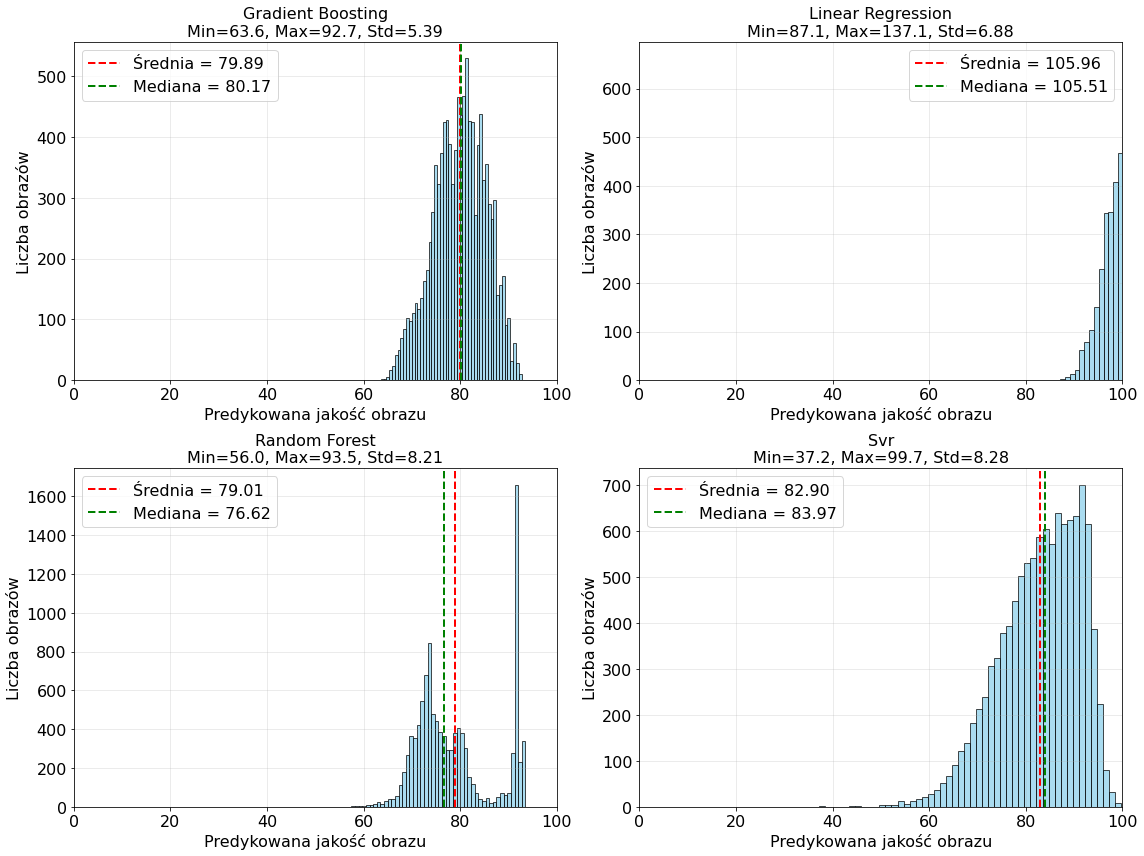


Statystyki predykcji jakości dla obrazów JFIF (wczytane modele):

Gradient Boosting:
  Średnia: 79.89
  Mediana: 80.17
  Odch. std.: 5.39
  Min: 63.56
  Max: 92.70
  Q1 (25%): 76.15
  Q3 (75%): 83.97

Linear Regression:
  Średnia: 105.96
  Mediana: 105.51
  Odch. std.: 6.88
  Min: 87.11
  Max: 137.10
  Q1 (25%): 101.04
  Q3 (75%): 110.26

Random Forest:
  Średnia: 79.01
  Mediana: 76.62
  Odch. std.: 8.21
  Min: 55.99
  Max: 93.49
  Q1 (25%): 72.80
  Q3 (75%): 87.59

Svr:
  Średnia: 82.90
  Mediana: 83.97
  Odch. std.: 8.28
  Min: 37.19
  Max: 99.73
  Q1 (25%): 77.47
  Q3 (75%): 89.58



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Parametr wielkości czcionki dla wszystkich wykresów
FONT_SIZE = 16

# Wczytanie danych JFIF
from_csv = pd.read_csv('results_jfif.csv')
from_csv = from_csv.dropna()
X_from_csv = from_csv.drop(['filename', 'extension', 'estimated_quality'], axis=1)

print(f"Dane JFIF wczytane: {len(X_from_csv)} próbek")
print("=" * 70)

# Predykcja jakości dla obrazów JFIF
y_pred_jfif_loaded = {}
for name, res in loaded_results.items():
    y_pred_jfif_loaded[name] = res['model'].predict(X_from_csv)
    print(f"✓ Predykcja wykonana: {name}")

print("\n" + "=" * 70)

# Wizualizacja predykcji dla wszystkich modeli
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.ravel()

for idx, (name, y_pred) in enumerate(y_pred_jfif_loaded.items()):
    # Histogram predykowanych wartości
    axes[idx].hist(y_pred, bins=50, alpha=0.7, edgecolor='black', color='skyblue')
    axes[idx].axvline(x=y_pred.mean(), color='r', linestyle='--', lw=2, 
                      label=f'Mean = {y_pred.mean():.2f}')
    axes[idx].axvline(x=np.median(y_pred), color='g', linestyle='--', lw=2, 
                      label=f'Median = {np.median(y_pred):.2f}')
    axes[idx].set_xlabel('Predicted image quality', fontsize=FONT_SIZE)
    axes[idx].set_ylabel('Number of images', fontsize=FONT_SIZE)
    axes[idx].set_title(f'{name}\nMin={y_pred.min():.1f}, Max={y_pred.max():.1f}, Std={y_pred.std():.2f}', 
                        fontsize=FONT_SIZE)
    # axes[idx].set_yscale('log')
    axes[idx].grid(True, alpha=0.3)
    axes[idx].legend(fontsize=FONT_SIZE)
    axes[idx].set_xlim(0, 100)
    axes[idx].tick_params(axis='both', which='major', labelsize=FONT_SIZE)

plt.tight_layout()
# plt.savefig('jfif_quality_predictions_loaded_models.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nStatystyki predykcji jakości dla obrazów JFIF (wczytane modele):")
print("="*70)
for name, y_pred in y_pred_jfif_loaded.items():
    print(f"\n{name}:")
    print(f"  Średnia: {y_pred.mean():.2f}")
    print(f"  Mediana: {np.median(y_pred):.2f}")
    print(f"  Odch. std.: {y_pred.std():.2f}")
    print(f"  Min: {y_pred.min():.2f}")
    print(f"  Max: {y_pred.max():.2f}")
    print(f"  Q1 (25%): {np.percentile(y_pred, 25):.2f}")
    print(f"  Q3 (75%): {np.percentile(y_pred, 75):.2f}")

print("\n" + "="*70)


# Predykcja na jednym modelu

Dane JFIF wczytane: 11338 próbek
✓ Predykcja wykonana: Random Forest



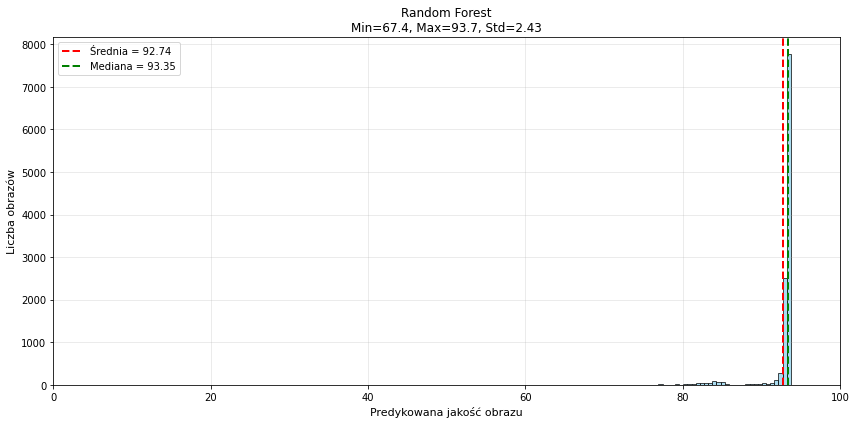


Statystyki predykcji jakości dla obrazów JFIF (Random Forest):
  Średnia: 92.74
  Mediana: 93.35
  Odch. std.: 2.43
  Min: 67.44
  Max: 93.74
  Q1 (25%): 93.14
  Q3 (75%): 93.47



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

FILENAME = "results_iFakeFaceDB.csv"
FILENAME = "results_ppm.csv"

# Wczytanie danych JFIF
from_csv = pd.read_csv(FILENAME)
from_csv = from_csv.dropna()
X_from_csv = from_csv.drop(['filename', 'extension', 'estimated_quality'], axis=1)

print(f"Dane JFIF wczytane: {len(X_from_csv)} próbek")
print("=" * 70)

# Wybierz jeden model (np. Gradient Boosting)
model_name = 'Random Forest'
model = loaded_results[model_name]['model']

# Predykcja jakości dla obrazów JFIF
y_pred = model.predict(X_from_csv)
print(f"✓ Predykcja wykonana: {model_name}")

print("\n" + "=" * 70)

# Wizualizacja predykcji
fig, ax = plt.subplots(figsize=(12, 6))

ax.hist(y_pred, bins=50, alpha=0.7, edgecolor='black', color='skyblue')
ax.axvline(x=y_pred.mean(), color='r', linestyle='--', lw=2, 
          label=f'Mean = {y_pred.mean():.2f}')
ax.axvline(x=np.median(y_pred), color='g', linestyle='--', lw=2, 
          label=f'Median = {np.median(y_pred):.2f}')
ax.set_xlabel('Predicted image quality', fontsize=FONT_SIZE)
ax.set_ylabel('Number of images', fontsize=FONT_SIZE)
ax.set_title(f'{model_name}\nMin={y_pred.min():.1f}, Max={y_pred.max():.1f}, Std={y_pred.std():.2f}', 
            fontsize=FONT_SIZE)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=FONT_SIZE)
ax.set_xlim(0, 100)
ax.tick_params(axis='both', which='major', labelsize=FONT_SIZE)

plt.tight_layout()
plt.savefig('jfif_quality_predictions_single_model.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\nStatystyki predykcji jakości dla obrazów JFIF ({model_name}):")
print("="*70)
print(f"  Średnia: {y_pred.mean():.2f}")
print(f"  Mediana: {np.median(y_pred):.2f}")
print(f"  Odch. std.: {y_pred.std():.2f}")
print(f"  Min: {y_pred.min():.2f}")
print(f"  Max: {y_pred.max():.2f}")
print(f"  Q1 (25%): {np.percentile(y_pred, 25):.2f}")
print(f"  Q3 (75%): {np.percentile(y_pred, 75):.2f}")
print("\n" + "="*70)


Dane JFIF wczytane: 46836 próbek
✓ Predykcja wykonana: Random Forest



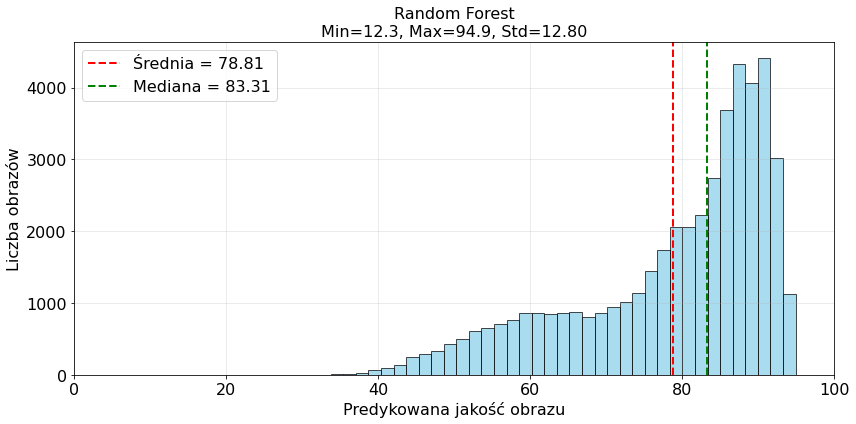


Statystyki predykcji jakości dla obrazów JFIF (Random Forest):
  Średnia: 78.81
  Mediana: 83.31
  Odch. std.: 12.80
  Min: 12.30
  Max: 94.90
  Q1 (25%): 71.65
  Q3 (75%): 88.68



In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt



FONT_SIZE = 16

FILENAME = "results_selfie-dataset.csv"
# FILENAME = "results_syntetyczne-digiface.csv"

# Wczytanie danych JFIF
from_csv = pd.read_csv(FILENAME)
from_csv = from_csv.dropna()
X_from_csv = from_csv.drop(['filename', 'extension', 'estimated_quality'], axis=1)

print(f"Dane JFIF wczytane: {len(X_from_csv)} próbek")
print("=" * 70)

# Wybierz jeden model (np. Gradient Boosting)
model_name = 'Random Forest'
model = loaded_results[model_name]['model']

# Predykcja jakości dla obrazów JFIF
y_pred = model.predict(X_from_csv)
print(f"✓ Predykcja wykonana: {model_name}")

print("\n" + "=" * 70)

# Wizualizacja predykcji
fig, ax = plt.subplots(figsize=(12, 6))

ax.hist(y_pred, bins=50, alpha=0.7, edgecolor='black', color='skyblue')
ax.axvline(x=y_pred.mean(), color='r', linestyle='--', lw=2, 
          label=f'Mean = {y_pred.mean():.2f}')
ax.axvline(x=np.median(y_pred), color='g', linestyle='--', lw=2, 
          label=f'Median = {np.median(y_pred):.2f}')
ax.set_xlabel('Predicted image quality', fontsize=FONT_SIZE)
ax.set_ylabel('Number of images', fontsize=FONT_SIZE)
ax.set_title(f'{model_name}\nMin={y_pred.min():.1f}, Max={y_pred.max():.1f}, Std={y_pred.std():.2f}', 
            fontsize=FONT_SIZE)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=FONT_SIZE)
ax.set_xlim(0, 100)
ax.tick_params(axis='both', which='major', labelsize=FONT_SIZE)

plt.tight_layout()
# plt.savefig('jfif_quality_predictions_single_model.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\nStatystyki predykcji jakości dla obrazów JFIF ({model_name}):")
print("="*70)
print(f"  Średnia: {y_pred.mean():.2f}")
print(f"  Mediana: {np.median(y_pred):.2f}")
print(f"  Odch. std.: {y_pred.std():.2f}")
print(f"  Min: {y_pred.min():.2f}")
print(f"  Max: {y_pred.max():.2f}")
print(f"  Q1 (25%): {np.percentile(y_pred, 25):.2f}")
print(f"  Q3 (75%): {np.percentile(y_pred, 75):.2f}")
print("\n" + "="*70)


# Nałożenie wielu zbiorów

<ipython-input-16-8c66d225f180>:41: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap('tab10', len(csv_paths))


✓ Predykcja wykonana: results_jfif (11000 próbek) [znormalizowano per-zbiór]
✓ Predykcja wykonana: results_ppm (11338 próbek) [znormalizowano per-zbiór]
✓ Predykcja wykonana: results_selfie-dataset (46836 próbek) [znormalizowano per-zbiór]


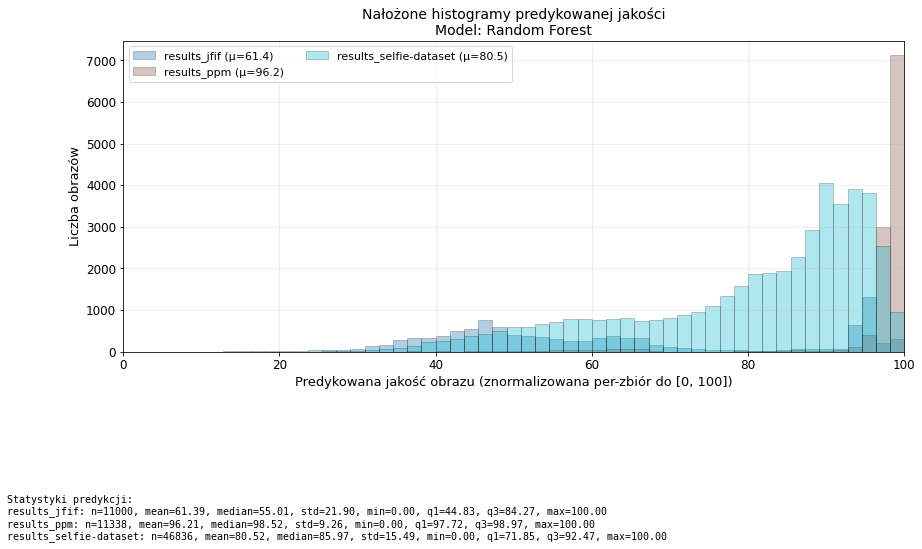


STATYSTYKI (tabela)


,dataset,n,mean,median,std,min,q1_25%,q3_75%,max
0,results_jfif,11000,61.393,55.013,21.899,0.0,44.827,84.273,100.0
1,results_ppm,11338,96.210,98.517,9.255,0.0,97.719,98.973,100.0
2,results_selfie-dataset,46836,80.519,85.969,15.493,0.0,71.852,92.470,100.0


In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

FONT_SIZE = 13

def _min_max_normalize_to_0_100(values):
    values = np.asarray(values, dtype=float)
    v_min = np.min(values)
    v_max = np.max(values)
    if np.isclose(v_min, v_max):
        # Jeśli wszystkie wartości są takie same, ustaw stałą wartość 50
        return np.full_like(values, 50.0, dtype=float)
    return (values - v_min) / (v_max - v_min) * 100.0

def plot_overlay_histograms_from_csv_list(
    csv_paths,
    dataset_names,
    loaded_results,
    model_name='Random Forest',
    bins=50,
    alpha=0.35,
    xlim=(0, 100),
    normalize_each_dataset=True,
):
    """
    Rysuje nałożone histogramy predykowanej jakości dla wielu plików CSV
    i wypisuje statystyki dla każdego zbioru.
    normalize_each_dataset=True: min-max normalizacja każdego zbioru osobno do [0, 100].
    """
    if len(csv_paths) != len(dataset_names):
        raise ValueError('csv_paths and dataset_names must have the same length.')

    if model_name not in loaded_results:
        raise ValueError(
            f"Model '{model_name}' nie jest w loaded_results. Dostępne: {list(loaded_results.keys())}"
        )

    model = loaded_results[model_name]['model']
    predictions = {}
    stats_rows = []

    # Spójna paleta kolorów dla wielu zbiorów
    cmap = plt.cm.get_cmap('tab10', len(csv_paths))

    for i, (csv_path, label) in enumerate(zip(csv_paths, dataset_names)):
        csv_path = Path(csv_path)
        if not csv_path.exists():
            print(f"⚠ Pominięto (brak pliku): {csv_path}")
            continue

        from_csv = pd.read_csv(csv_path).dropna()

        required_drop_cols = ['filename', 'extension', 'estimated_quality']
        existing_drop_cols = [c for c in required_drop_cols if c in from_csv.columns]
        X_from_csv = from_csv.drop(existing_drop_cols, axis=1)

        if X_from_csv.empty:
            print(f"⚠ Pominięto (brak cech po drop): {csv_path}")
            continue

        y_pred_raw = model.predict(X_from_csv)
        y_pred = _min_max_normalize_to_0_100(y_pred_raw) if normalize_each_dataset else y_pred_raw
        predictions[label] = y_pred

        stats_rows.append({
            'dataset': label,
            'n': len(y_pred),
            'mean': float(np.mean(y_pred)),
            'median': float(np.median(y_pred)),
            'std': float(np.std(y_pred)),
            'min': float(np.min(y_pred)),
            'q1_25%': float(np.percentile(y_pred, 25)),
            'q3_75%': float(np.percentile(y_pred, 75)),
            'max': float(np.max(y_pred)),
            'color': cmap(i),
        })

        suffix = ' [znormalizowano per-zbiór]' if normalize_each_dataset else ''
        print(f"✓ Predykcja wykonana: {label} ({len(y_pred)} próbek){suffix}")

    if not predictions:
        raise ValueError("Brak poprawnych danych do narysowania wykresu.")

    fig, ax = plt.subplots(figsize=(14, 8))

    for i, (label, y_pred) in enumerate(predictions.items()):
        color = cmap(i)
        ax.hist(
            y_pred,
            bins=bins,
            alpha=alpha,
            edgecolor='black',
            linewidth=0.6,
            color=color,
            label=f"{label} (μ={np.mean(y_pred):.1f})",
        )

    ax.set_xlabel(
        'Predicted image quality (normalized per dataset to [0, 100])' if normalize_each_dataset else 'Predicted image quality',
        fontsize=FONT_SIZE,
    )
    ax.set_ylabel('Number of images', fontsize=FONT_SIZE)
    ax.set_title(f'Overlaid histograms of predicted quality\nModel: {model_name}', fontsize=FONT_SIZE + 1)
    ax.set_xlim(*xlim)
    ax.grid(True, alpha=0.25)
    ax.legend(fontsize=FONT_SIZE - 2, ncol=2)
    ax.tick_params(axis='both', which='major', labelsize=FONT_SIZE - 1)

    # Tekst ze statystykami pod wykresem
    stats_df = pd.DataFrame(stats_rows).drop(columns=['color'])
    stats_df = stats_df.sort_values('dataset').reset_index(drop=True)

    stats_text_lines = ["Prediction statistics:"]
    for _, row in stats_df.iterrows():
        stats_text_lines.append(
            f"{row['dataset']}: n={int(row['n'])}, mean={row['mean']:.2f}, median={row['median']:.2f}, std={row['std']:.2f}, "
            f"min={row['min']:.2f}, q1={row['q1_25%']:.2f}, q3={row['q3_75%']:.2f}, max={row['max']:.2f}"
        )

    plt.subplots_adjust(bottom=0.34)
    fig.text(
        0.01,
        0.01,
        "\n".join(stats_text_lines),
        ha='left',
        va='bottom',
        fontsize=10,
        family='monospace',
    )

    plt.show()

    print("\n" + "=" * 100)
    print("STATYSTYKI (tabela)")
    print("=" * 100)
    display(stats_df.round(3))

    return stats_df, predictions

# Przykładowe użycie: lista plików CSV do porównania rozkładów
CSV_PATHS = [
    'results_jfif.csv',
    'results_ppm.csv',
    'results_selfie-dataset.csv',
    # 'results_iFakeFaceDB.csv',
]
DATASET_NAMES = [
    'JFIF',
    'PPM',
    'Selfie Dataset',
    # 'iFakeFaceDB',
]

stats_df, predictions = plot_overlay_histograms_from_csv_list(
    csv_paths=CSV_PATHS,
    dataset_names=DATASET_NAMES,
    loaded_results=loaded_results,
    model_name='Random Forest',
    bins=55,
    alpha=0.35,
    xlim=(0, 100),
    normalize_each_dataset=True,
)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

FONT_SIZE = 13


def _min_max_normalize_to_0_100(values):
    values = np.asarray(values, dtype=float)
    v_min = np.min(values)
    v_max = np.max(values)
    if np.isclose(v_min, v_max):
        return np.full_like(values, 50.0, dtype=float)
    return (values - v_min) / (v_max - v_min) * 100.0


def plot_line_envelopes_from_csv_list(
    csv_paths,
    dataset_names,
    loaded_results,
    model_name='Random Forest',
    bins=55,
    xlim=(0, 100),
    normalize_each_dataset=True,
    density=False,
):
    """
    Rysuje obwiednie histogramów (wykresy liniowe) predykowanej jakości
    dla wielu plików CSV na jednym wykresie.
    normalize_each_dataset=True: min-max normalizacja każdego zbioru osobno do [0, 100].
    density=True: oś Y jako gęstość znormalizowana, False: liczba obrazów.
    """
    if len(csv_paths) != len(dataset_names):
        raise ValueError('csv_paths and dataset_names must have the same length.')

    if model_name not in loaded_results:
        raise ValueError(
            f"Model '{model_name}' nie jest w loaded_results. "
            f"Dostępne: {list(loaded_results.keys())}"
        )

    model = loaded_results[model_name]['model']
    cmap = plt.cm.get_cmap('tab10', len(csv_paths))
    stats_rows = []
    plot_data = []

    for i, (csv_path, label) in enumerate(zip(csv_paths, dataset_names)):
        csv_path = Path(csv_path)
        if not csv_path.exists():
            print(f"⚠ Pominięto (brak pliku): {csv_path}")
            continue

        from_csv = pd.read_csv(csv_path).dropna()
        required_drop_cols = ['filename', 'extension', 'estimated_quality']
        existing_drop_cols = [c for c in required_drop_cols if c in from_csv.columns]
        X_from_csv = from_csv.drop(existing_drop_cols, axis=1)

        if X_from_csv.empty:
            print(f"⚠ Pominięto (brak cech po drop): {csv_path}")
            continue

        y_pred_raw = model.predict(X_from_csv)
        y_pred = _min_max_normalize_to_0_100(y_pred_raw) if normalize_each_dataset else y_pred_raw
        color = cmap(i)

        counts, bin_edges = np.histogram(y_pred, bins=bins, range=xlim, density=density)
        bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

        plot_data.append((label, bin_centers, counts, color, y_pred))

        stats_rows.append({
            'dataset': label,
            'n': len(y_pred),
            'mean': float(np.mean(y_pred)),
            'median': float(np.median(y_pred)),
            'std': float(np.std(y_pred)),
            'min': float(np.min(y_pred)),
            'q1_25%': float(np.percentile(y_pred, 25)),
            'q3_75%': float(np.percentile(y_pred, 75)),
            'max': float(np.max(y_pred)),
        })

        suffix = ' [znormalizowano per-zbiór]' if normalize_each_dataset else ''
        print(f"✓ Predykcja wykonana: {label} ({len(y_pred)} próbek){suffix}")

    if not plot_data:
        raise ValueError("Brak poprawnych danych do narysowania wykresu.")

    fig, ax = plt.subplots(figsize=(14, 8))

    for label, bin_centers, counts, color, y_pred in plot_data:
        ax.plot(
            bin_centers, counts,
            color=color, lw=2,
            label=f"{label} (μ={np.mean(y_pred):.1f})",
        )
        ax.fill_between(bin_centers, counts, alpha=0.08, color=color)

    ylabel = 'Gęstość' if density else 'Number of images'
    xlabel = (
        'Predicted image quality (normalized per dataset to [0, 100])'
        if normalize_each_dataset else 'Predicted image quality'
    )
    ax.set_xlabel(xlabel, fontsize=FONT_SIZE)
    ax.set_ylabel(ylabel, fontsize=FONT_SIZE)
    ax.set_title(
        f'Predicted quality distribution envelopes\nModel: {model_name}',
        fontsize=FONT_SIZE + 1,
    )
    ax.set_xlim(*xlim)
    ax.set_ylim(bottom=0)
    ax.grid(True, alpha=0.25)
    ax.legend(fontsize=FONT_SIZE - 2, ncol=2)
    ax.tick_params(axis='both', which='major', labelsize=FONT_SIZE - 1)

    stats_df = pd.DataFrame(stats_rows).sort_values('dataset').reset_index(drop=True)

    stats_text_lines = ["Prediction statistics:"]
    for _, row in stats_df.iterrows():
        stats_text_lines.append(
            f"{row['dataset']}: n={int(row['n'])}, mean={row['mean']:.2f}, "
            f"median={row['median']:.2f}, std={row['std']:.2f}, "
            f"min={row['min']:.2f}, q1={row['q1_25%']:.2f}, "
            f"q3={row['q3_75%']:.2f}, max={row['max']:.2f}"
        )

    n_text_lines = len(stats_text_lines)
    bottom_margin = max(0.20, 0.04 * n_text_lines)
    plt.subplots_adjust(bottom=bottom_margin)
    fig.text(
        0.01, 0.01,
        "\n".join(stats_text_lines),
        ha='left', va='bottom',
        fontsize=10, family='monospace',
    )

    plt.show()

    print("\n" + "=" * 100)
    print("STATYSTYKI (tabela)")
    print("=" * 100)
    display(stats_df.round(3))

    return stats_df


CSV_PATHS = [
    'results_jfif.csv',
    'results_ppm.csv',
    'results_selfie-dataset.csv',
    # 'results_iFakeFaceDB.csv',
]
DATASET_NAMES = [
    'JFIF',
    'PPM',
    'Selfie Dataset',
    # 'iFakeFaceDB',
]

plot_line_envelopes_from_csv_list(
    csv_paths=CSV_PATHS,
    dataset_names=DATASET_NAMES,
    loaded_results=loaded_results,
    model_name='Random Forest',
    bins=55,
    xlim=(0, 100),
    normalize_each_dataset=True,
    density=False,
)


# Predykcja jednostkowo - live

In [28]:
from index_script import detect_jpeg_compression
import os

def check_image(image_path):
    if not os.path.exists(image_path):
        print(f"Błąd: Plik '{image_path}' nie istnieje!")
        return
    
    print(f"Analiza pliku: {image_path}")
    
    result = detect_jpeg_compression(image_path)
    
    if result is None:
        print("Nie udało się obliczyć wskaźników")
        return
    
    # # Wyświetl wskaźniki
    # print("\nObliczone wskaźniki:")
    # for key, value in result.items():
    #     if key not in ['filename', 'extension']:
    #         if isinstance(value, float):
    #             print(f"{key:20s}: {value:.4f}")
    #         else:
    #             print(f"{key:20s}: {value}")
    
    #loaded_feature_columns = ['filename', 'extension', 'estimated_quality']
    loaded_feature_columns = ['blockiness_0', 'blockiness_1', 'blockiness_2', 'blockiness_3', 'blockiness_4', 'blockiness_5', 'blockiness_6', 'blockiness_7', 'blockiness_max', 'blockiness_mean', 'blockiness_std', 'energy_mean', 'energy_std', 'psnr']
    # Przygotuj dane do predykcji
    feature_dict = {col: result.get(col, 0) for col in loaded_feature_columns}
    X_single = pd.DataFrame([feature_dict])
    
    if X_single.isnull().any().any():
        print("\nBrakujące dane w wskaźnikach:")
        print(X_single.isnull().sum()[X_single.isnull().sum() > 0])
        return
    
    # Wybierz jeden model (np. Gradient Boosting)
    model_name = 'Random Forest'
    model = loaded_results[model_name]['model']

    # Predykcja jakości dla obrazów JFIF
    y_pred = model.predict(X_single)

    print(f"\nPredykowana jakość obrazu ({model_name}): {y_pred[0]:.2f}")
    print("-" * 80)


In [41]:
image_path = r"C:\Users\01sok\Downloads\test-224-224-1do1.png"


# check_image(r"C:\Users\01sok\Downloads\00001_930831_fa_a.ppm")
# check_image(r"C:\Users\01sok\Downloads\test-500-700q95.jpg")
# check_image(r"C:\Users\01sok\Downloads\test-500-700q80.jpg")
# check_image(r"C:\Users\01sok\Downloads\test-500-700q80.png")
# check_image(r"C:\Users\01sok\Downloads\test-500-700q60.jpg")
# check_image(r"C:\Users\01sok\Downloads\test-224-224-1do1.png")
# check_image(r"C:\Users\01sok\Downloads\test-500-700q60q100.jpg")

# check_image(r"C:\Users\01sok\Downloads\test-500-700q80-1do1.png")
# check_image(r"C:\Users\01sok\Downloads\test-500-700q80-1do1-doPNG-400-400.png")
# check_image(r"C:\Users\01sok\Downloads\test-500-700q80-1do1-doPNG-350-350.png")

check_image(r"C:\Users\01sok\Downloads\fakeface.jpg")
check_image(r"C:\Users\01sok\Downloads\fakeface-100x100.png")
check_image(r"C:\Users\01sok\Downloads\fakeface-500x500.png")
check_image(r"C:\Users\01sok\Downloads\fakeface-250x250.png")
check_image(r"C:\Users\01sok\Downloads\test-500-700q60q100-1000x1500.png")

Analiza pliku: C:\Users\01sok\Downloads\fakeface.jpg

Predykowana jakość obrazu (Random Forest): 64.25
--------------------------------------------------------------------------------
Analiza pliku: C:\Users\01sok\Downloads\fakeface-100x100.png

Predykowana jakość obrazu (Random Forest): 42.85
--------------------------------------------------------------------------------
Analiza pliku: C:\Users\01sok\Downloads\fakeface-500x500.png

Predykowana jakość obrazu (Random Forest): 93.03
--------------------------------------------------------------------------------
Analiza pliku: C:\Users\01sok\Downloads\fakeface-250x250.png

Predykowana jakość obrazu (Random Forest): 93.18
--------------------------------------------------------------------------------
Analiza pliku: C:\Users\01sok\Downloads\test-500-700q60q100-1000x1500.png

Predykowana jakość obrazu (Random Forest): 93.39
--------------------------------------------------------------------------------
